# El experimento ganador: slotting por merchant con batches armados por pasillo

Este notebook junta en un solo lugar el experimento que mejor resultado dio hasta ahora, con todos
sus modelos y parametros a la vista, para que se pueda leer sin los notebooks anteriores.

**Pregunta.** Cuanto baja la caminata de los pickers un slotting que incorpora la afinidad que
tienen los datos, y de que depende esa ganancia.

**Que se compara.** Cuatro slottings, el vigente del deposito y tres calculados, bajo dos formas de
armar los batches: la de los datos, que junta 25 ordenes consecutivas (FIFO), y un re-batching que
junta ordenes que necesitan los mismos pasillos. Todo se mide simulando el periodo de test, con el
picker recorriendo los pasillos en S.

**Contenido.**
0. Configuracion: todos los parametros.
1. Datos y particion.
2. La afinidad que tienen los datos.
3. El recorrido en S.
4. El slotting ganador.
5. Como se arman los batches.
6. Como se simula.
7. Resultados en `medium`.
8. Sensibilidad a la politica de reposicion.
9. Otros depositos.
10. Los demas metodos probados.
11. Lectura.

## 0. Configuracion

Todos los parametros del experimento. La ultima columna dice si el resultado ganador depende de cada
uno; los que no, se usan solo en comparaciones.

| componente | parametro | valor | que hace | lo usa el ganador |
|---|---|---|---|---|
| datos | deposito | `medium` | carpeta de `data/v2`; la seccion 9 repite con `small`, `medium-alpha-1.3` y `big` | si |
| particion | fraccion de test | 0,2 | los batches se ordenan por la hora de su primera linea; el ultimo 20% es test | si |
| instancia | demanda $f_i$ | `pick_lines` | fraccion de las lineas de train que piden el SKU $i$ | si |
| instancia | costo $c_l$ | distancia caminando de la bay de la ubicacion $l$ al dock | ordena las ubicaciones | si |
| instancia | afinidad $a_{ij}$ | `jaccard` sobre las ordenes de train, 10 vecinos por SKU, normalizada | termino cuadratico del QAP | no: solo la reposicion `objective_greedy` (seccion 8) |
| instancia | distancia entre ubicaciones | `aisle`: 0 en el mismo pasillo, largo del pasillo mas la distancia lateral si no | idem | no: idem |
| ruteo | recorrido | `s_shape` | S estricto (seccion 3) | si |
| slotting | metodo | `merchant_aisle_fill` | regla de la seccion 4; no tiene parametros | si |
| batching | ordenes por batch | 25 | igual que en los datos (hecho 2) | si |
| batching | ventana $W$ | 4; se barre 1, 2, 4, 8 y 16 | cuantos batches FIFO consecutivos se re-arman juntos; 1 es FIFO | si |
| batching | pasadas de intercambios | 20 | tope de la mejora local (seccion 5.3) | si |
| espera | minutos por franja | el de los datos: 32 en `medium` | pasa la espera a minutos (seccion 5.5) | solo para medir |
| simulacion | reposicion | `home` | cada reposicion va a la ubicacion del plan (seccion 6) | si |
| simulacion | reposiciones alternativas | `objective_greedy` con $\lambda = 0{,}5$; `random` con probabilidad de mudanza 0,9 y semilla 0 | seccion 8 | no |
| simulacion | costo de llevar el deposito al plan | no se cuenta | el plan se aplica al estado del corte de una sola vez | |

In [1]:
# Librerias y piezas del paquete.
import gc
import inspect
import json
import time
from collections import Counter
from types import SimpleNamespace

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from abs_affinity_based_slotting.config import PROJECT_ROOT, dataset_dir
from abs_affinity_based_slotting.data import WarehouseDataLoader, split_picking_events
from abs_affinity_based_slotting.demand import TopKFilter
from abs_affinity_based_slotting.slotting import build_full_instance, Assignment
from abs_affinity_based_slotting.methods import method_registry
from abs_affinity_based_slotting.methods import aisle_fill as modulo_aisle_fill
from abs_affinity_based_slotting.simulation import (Simulator, split_replenishments, build_event_stream,
                                                    state_from_initial_stock, state_after_history, reslot_state,
                                                    replenishment_policy_registry)
from abs_affinity_based_slotting.batching import FifoBatching, AisleCoverBatching, orders_by_arrival, order_waits

pd.set_option("display.width", 160)

# ---- configuracion (tabla de arriba)
DATASET = "medium"
OTROS = ["small", "medium-alpha-1.3", "big"]
TEST_SIZE = 0.2
INSTANCIA = dict(demand_metric="pick_lines",                 # f_i
                 affinity_metric="jaccard", cooccurrence_col="order_id",
                 affinity_filter=TopKFilter(k=10), normalize=True,
                 pair_distance_model="aisle")                 # a_ij y distancia: solo objective_greedy
BATCH_SIZE = 25
VENTANA = 4                                                   # la ventana del experimento ganador
VENTANAS = [1, 2, 4, 8, 16]
MAX_PASSES = 20
REPOSICION = "home"
LAM_OBJECTIVE_GREEDY = 0.5
SEMILLA = 0
GANADOR = "merchant_aisle_fill"
PLANES = ["vigente", "demand_greedy", "aisle_fill", "merchant_aisle_fill"]
COLORES = {"demand_greedy": "#2a78d6", "aisle_fill": "#eb6834", "merchant_aisle_fill": "#1baf7a", "vigente": "#eda100"}

## 1. Datos y particion

Los datos son un deposito sintetico que genero ShipHero: seis meses de lineas de picking con la orden
y el batch de cada una, el stock inicial, las reposiciones y el plano. Las piezas del paquete que los
preparan, en el orden en que se usan:

- `split_picking_events` ordena los batches por la hora de su primera linea y deja el ultimo 20% como
  test. Los planes se calculan con train; todo se mide en test.
- `build_full_instance` arma la instancia: los indices de SKUs, ubicaciones y bays, la demanda $f_i$ y
  el costo $c_l$ de la tabla de la seccion 0.
- `state_after_history` reproduce todo lo que paso en train sobre el stock inicial y da el estado real
  del deposito al corte: que SKU hay en cada ubicacion y con cuantas unidades.
- `Simulator` reproduce sobre un estado las lineas y las reposiciones de test, y camina cada batch con
  el recorrido en S.

Todo va en una funcion para repetirlo en la seccion 9 con otros depositos.

In [2]:
def preparar(nombre):
    # Datos, instancia, estado al corte y simulador con recorrido en S, para una carpeta de data/v2.
    ds = WarehouseDataLoader(dataset_dir("v2", nombre)).load_all()
    split = split_picking_events(ds.picking_events, test_size=TEST_SIZE)
    instance = build_full_instance(split.train, ds.initial_stock, ds.distances, coordinates=ds.coordinates, **INSTANCIA)
    # las reposiciones se cortan en el mismo momento que el picking
    replen_train, replen_test = split_replenishments(ds.replenishment_events, split.train, ds.initial_stock, split.cutoff)
    state0 = state_from_initial_stock(instance, ds.initial_stock)                          # dia cero
    state_cut, _ = state_after_history(state0, build_event_stream(split.train, replen_train, instance), instance)
    sim = Simulator.from_tables(instance, ds.coordinates, routing="s_shape")
    inicio = ds.picking_events.groupby("batch_id")["timestamp"].min().sort_values()
    return SimpleNamespace(nombre=nombre, ds=ds, split=split, instance=instance, replen_test=replen_test,
                           state_cut=state_cut, sim=sim, costo=sim.routing.mask_costs(),
                           minutos_por_batch=float(inicio.diff().dt.total_seconds().median() / 60))


ctx = preparar(DATASET)
inst, train, test = ctx.instance, ctx.split.train, ctx.split.test
pd.Series({"pasillos": ctx.sim.routing.n_aisles, "ubicaciones": inst.n_locations, "SKUs": inst.n_skus,
           "merchants": len(set(inst.merchant_ids)),
           "ordenes de train": train["order_id"].nunique(), "ordenes de test": test["order_id"].nunique(),
           "batches de train": train["batch_id"].nunique(), "batches de test": test["batch_id"].nunique(),
           "corte entre train y test": ctx.split.cutoff}, name=DATASET).to_frame()

,medium
pasillos,8
ubicaciones,7680
SKUs,6912
merchants,50
ordenes de train,162900
ordenes de test,40725
batches de train,6516
batches de test,1629
corte entre train y test,2026-05-25 19:12:22.733333


Cuatro hechos de los datos que se usan mas adelante. **Hecho 1:** cada orden tiene SKUs de un solo merchant.

In [3]:
merchants_por_orden = ctx.ds.picking_events.groupby("order_id")["merchant_account_id"].nunique()
print("merchants distintos por orden:", merchants_por_orden.value_counts().to_dict())

merchants distintos por orden: {1: 203625}


**Hecho 2:** todos los batches tienen 25 ordenes y sale uno nuevo a ritmo constante. Los datos no
traen la hora en que llega cada orden, solo el orden en que entraron a los batches.

In [4]:
# Sobre los seis meses completos.
todo = ctx.ds.picking_events
ordenes_por_batch = todo.groupby("batch_id")["order_id"].nunique()
por_dia = todo.groupby("batch_id")["timestamp"].min().dt.date.value_counts()
print("ordenes por batch:", ordenes_por_batch.min(), "a", ordenes_por_batch.max())
print("batches por dia:", por_dia.min(), "a", por_dia.max())
print(f"sale un batch cada {ctx.minutos_por_batch:.1f} minutos (mediana)")

ordenes por batch: 25 a 25
batches por dia: 45 a 45
sale un batch cada 32.0 minutos (mediana)


**Hecho 3:** al corte, cada SKU esta en exactamente una ubicacion. Asi el slotting vigente es un plan bien definido.

In [5]:
ubicaciones_por_sku = pd.Series([len(ctx.state_cut.locations_of(s)) for s in range(inst.n_skus)])
print("ubicaciones por SKU al corte:", ubicaciones_por_sku.value_counts().to_dict())

ubicaciones por SKU al corte: {1: 6912}


**Hecho 4:** ninguna orden pide dos veces el mismo SKU, asi que contar lineas de un SKU es contar ordenes que lo piden.

In [6]:
print("lineas:", len(todo), "| pares (orden, SKU) distintos:", len(todo.drop_duplicates(["order_id", "sku"])))

lineas: 712137 | pares (orden, SKU) distintos: 712137


## 2. La afinidad que tienen los datos

Antes de usar la afinidad hay que ver cuanta hay y de que forma. Se mide sobre las ordenes de train,
que es donde dos productos se piden juntos.

### 2.1 Co-ocurrencia contra independencia

Sean $N$ la cantidad de ordenes, $s_i$ cuantas piden el SKU $i$ y $n_{ij}$ cuantas piden a la vez los
SKUs $i$ y $j$. Si los SKUs se pidieran de forma independiente, cada orden tendria a $i$ con
probabilidad $s_i/N$ y a $j$ con probabilidad $s_j/N$, y el valor esperado de $n_{ij}$ seria
$$E[n_{ij}] = N \cdot \frac{s_i}{N} \cdot \frac{s_j}{N} = \frac{s_i\, s_j}{N}.$$
La tabla compara, sumando sobre todos los pares, lo observado con ese esperado, separando los pares de
SKUs del mismo merchant y los de merchants distintos.

In [7]:
lineas_train = train[["order_id", "sku", "merchant_account_id"]]
orden = pd.factorize(lineas_train["order_id"])[0]                 # indice de orden de cada linea
sku, nombres_sku = pd.factorize(lineas_train["sku"])              # indice de SKU de cada linea
merchant = pd.factorize(lineas_train["merchant_account_id"])[0]   # indice de merchant de cada linea
merchant_de_sku = pd.Series(merchant).groupby(sku).first().sort_index().to_numpy()


def conteo_de_pares(orden, sku):
    # n_ij para cada par de SKUs (i < j) que aparece junto en al menos una orden.
    d = pd.DataFrame({"o": orden, "s": sku})
    m = d.merge(d, on="o")
    return m[m["s_x"] < m["s_y"]].groupby(["s_x", "s_y"]).size()


n_obs = conteo_de_pares(orden, sku)
N = orden.max() + 1
s = np.bincount(sku)                                              # s_i (hecho 4: lineas = ordenes)
mismo = merchant_de_sku[n_obs.index.get_level_values(0)] == merchant_de_sku[n_obs.index.get_level_values(1)]

# Suma de s_i s_j / N sobre todos los pares i < j: ((sum s)^2 - sum s^2) / 2 / N, dentro de cada merchant y en total.
suma_pares = lambda x: (x.sum() ** 2 - (x ** 2).sum()) / 2
esperado_mismo = pd.Series(s).groupby(merchant_de_sku).agg(suma_pares).sum() / N
esperado_total = suma_pares(s) / N
afinidad = pd.DataFrame({"suma de n_ij observada": [n_obs[mismo].sum(), n_obs[~mismo].sum()],
                         "suma esperada si fueran independientes": [esperado_mismo, esperado_total - esperado_mismo]},
                        index=["pares del mismo merchant", "pares de merchants distintos"])
afinidad["observado / esperado"] = afinidad.iloc[:, 0] / afinidad.iloc[:, 1]
print("ordenes de train:", N, "| pares con n_ij > 0:", len(n_obs))
afinidad.round(1)

ordenes de train: 162900 | pares con n_ij > 0: 147489


,suma de n_ij observada,suma esperada si fueran independientes,observado / esperado
pares del mismo merchant,812538,18719.3,43.4
pares de merchants distintos,0,975509.9,0.0


Toda la co-ocurrencia de los datos esta dentro de los merchants. Dos SKUs del mismo merchant se piden
juntos 43,4 veces mas de lo que daria la independencia (812.538 contra 18.719), y dos SKUs de
merchants distintos no aparecen nunca en la misma orden, cuando la independencia daria 975.510
co-ocurrencias. Es el hecho 1 visto desde los pares: una orden elige sus SKUs entre los de un solo
merchant, unos 140, y no entre los 6.912 del deposito.

### 2.2 Dentro de un merchant, hay mas afinidad?

Puede haber pares de SKUs de un mismo merchant que se piden juntos mas que el resto, por ejemplo un
producto y su accesorio. Para verlo se compara la co-ocurrencia real con la de los mismos datos
barajados de una forma que borra cualquier afinidad entre SKUs y conserva todo lo demas.

**Como se baraja.** Dentro de cada merchant se reparten al azar sus SKUs entre sus lineas.
1. Se permuta al azar la columna de SKU entre las lineas de cada merchant. Eso conserva cuantas lineas
   tiene cada orden, cuantas veces aparece cada SKU y el merchant de cada orden.
2. La permutacion puede dejar un SKU repetido en una orden, que en los datos no pasa (hecho 4). Cada
   linea repetida se intercambia con una linea al azar del mismo merchant, de otra orden, siempre que
   el intercambio no cree otro repetido. Esto conserva lo mismo que el paso 1.

Es la idea de la *swap randomization* de Gionis et al. (2007). En los datos barajados un SKU sale con
otro solo por azar, por su popularidad y porque comparten merchant. Si la co-ocurrencia real se parece
a la barajada, no hay afinidad entre SKUs mas alla de esas tres cosas. Se repite con 20 semillas.

In [8]:
def barajar(orden, sku, merchant, semilla):
    # SKUs repartidos al azar dentro de cada merchant, sin repetidos en una orden (pasos 1 y 2).
    rng = np.random.default_rng(semilla)
    nuevo = sku.copy()
    lineas_de = [np.flatnonzero(merchant == m) for m in range(merchant.max() + 1)]
    for ids in lineas_de:                                          # paso 1
        nuevo[ids] = nuevo[rng.permutation(ids)]
    en_orden = [Counter() for _ in range(orden.max() + 1)]         # cuantas veces esta cada SKU en cada orden
    for o, x in zip(orden, nuevo):
        en_orden[o][x] += 1
    for i in range(len(orden)):                                    # paso 2
        o = orden[i]
        while en_orden[o][nuevo[i]] > 1:
            ids = lineas_de[merchant[i]]
            j = ids[rng.integers(len(ids))]
            a, b, p = nuevo[i], nuevo[j], orden[j]
            if p != o and en_orden[o][b] == 0 and en_orden[p][a] == 0:
                en_orden[o][a] -= 1; en_orden[o][b] += 1
                en_orden[p][b] -= 1; en_orden[p][a] += 1
                nuevo[i], nuevo[j] = b, a
    return nuevo


# Control: el barajado conserva lo que dice conservar.
b0 = barajar(orden, sku, merchant, 0)
print("misma frecuencia de cada SKU:", (np.bincount(b0, minlength=len(s)) == s).all())
print("mismo merchant en cada linea:", (merchant_de_sku[b0] == merchant).all())
print("SKUs repetidos en una orden:", int(pd.DataFrame({"o": orden, "s": b0}).duplicated().sum()))
print("SKUs que cambiaron de orden:", f"{(b0 != sku).mean():.0%} de las lineas")

misma frecuencia de cada SKU: True
mismo merchant en cada linea: True
SKUs repetidos en una orden: 0
SKUs que cambiaron de orden: 94% de las lineas


In [9]:
UMBRALES = [1, 2, 5, 10, 20, 50, 100, 200, 400]


def perfil_de_pares(n):
    # Cuantos pares tienen n_ij >= k, para cada umbral k, y el maximo de n_ij.
    return [int((n >= k).sum()) for k in UMBRALES] + [int(n.max())]


filas_b = [perfil_de_pares(conteo_de_pares(orden, barajar(orden, sku, merchant, semilla))) for semilla in range(20)]
nombres = [f"pares con n_ij >= {k}" for k in UMBRALES] + ["maximo de n_ij"]
barajado = pd.DataFrame(filas_b, columns=nombres)
pd.DataFrame({"datos": perfil_de_pares(n_obs), "barajado: minimo": barajado.min(),
              "barajado: media": barajado.mean().round(0), "barajado: maximo": barajado.max()}, index=nombres)

,datos,barajado: minimo,barajado: media,barajado: maximo
pares con n_ij >= 1,147489,147370,147718.0,148072
pares con n_ij >= 2,73011,72657,72842.0,73091
pares con n_ij >= 5,29346,29201,29355.0,29472
pares con n_ij >= 10,14295,14342,14401.0,14496
pares con n_ij >= 20,6462,6412,6474.0,6506
pares con n_ij >= 50,2178,2164,2185.0,2200
pares con n_ij >= 100,914,905,917.0,930
pares con n_ij >= 200,346,345,351.0,356
pares con n_ij >= 400,107,103,105.0,108
maximo de n_ij,819,776,793.0,808


Los datos y los barajados dan practicamente la misma distribucion. Para cada umbral, la cantidad de
pares con al menos esa co-ocurrencia difiere en menos del 2% de la media de los barajados, y en 8 de
los 9 umbrales cae entre su minimo y su maximo. El par mas frecuente de los datos (819 ordenes) queda
apenas por encima del maximo de los barajados (808), pero la cantidad de pares con 200 o 400
co-ocurrencias coincide, asi que no hay un grupo de pares con afinidad propia. Dentro de un merchant
los SKUs se piden juntos segun su popularidad y nada mas.

### 2.3 Que afinidad usar

La afinidad que tienen estos datos es una sola y es fuerte: **dos SKUs del mismo merchant**. Un
slotting que la incorpore tiene que mantener juntos los SKUs de cada merchant. La seccion 3 muestra
que, con recorrido en S, "juntos" quiere decir en el mismo pasillo, y la seccion 4 da la regla.

## 3. El recorrido en S

El picker sale del dock y va al frente del pasillo con picks que esta mas a la izquierda. Lo recorre
entero hasta el fondo, cruza al siguiente pasillo con picks y lo recorre entero hacia el frente, y asi
alternando; los pasillos sin picks se saltean. Si recorrio una cantidad impar de pasillos termina en
el fondo y vuelve al frente recorriendo el ultimo otra vez. Despues regresa al dock. Es como recorre
la operacion de ShipHero.

Para los pasillos visitados $S = \{a_1 < \dots < a_m\}$, el largo del recorrido es

$$R_S(S) = \underbrace{d_0(a_1)}_{\text{ida}} + \underbrace{m\,L}_{\text{recorrer cada pasillo}}
+ \underbrace{x_{a_m} - x_{a_1}}_{\text{cruces entre pasillos}}
+ \underbrace{[\,m \text{ impar}\,]\,L}_{\text{volver al frente}} + \underbrace{d_0(a_m)}_{\text{regreso}},
\qquad d_0(a) = |x_a - x_{\text{dock}}| + (y_0 - y_{\text{dock}}),$$

con $L$ el largo de un pasillo, $x_a$ su coordenada lateral, $y_0$ la coordenada del frente de los
pasillos y $d_0(a)$ la distancia del dock al frente del pasillo $a$.

**Ningun termino depende de en que bay del pasillo esta cada pick: el largo depende solo de que
pasillos se visitan.** Por eso, con este recorrido, la afinidad sirve para decidir que SKUs comparten
pasillo, y no para acercarlos dentro de un pasillo.

In [10]:
# La geometria, leida de la tabla de coordenadas (pulgadas).
r = ctx.sim.routing
print(f"{r.n_aisles} pasillos | largo L = {r.aisle_length:.0f} | frente en y0 = {r.front_y:.0f} | dock en {r.dock_xy}")
print("coordenada lateral x_a de cada pasillo:", r.aisle_x.tolist())

8 pasillos | largo L = 1776 | frente en y0 = 168 | dock en (0.0, -200.0)
coordenada lateral x_a de cada pasillo: [96.0, 288.0, 480.0, 672.0, 864.0, 1056.0, 1248.0, 1440.0]


La formula a mano, contra lo que calcula el paquete (`SShapeRouting.distance_of_aisles`):

In [11]:
d0 = lambda a: abs(r.aisle_x[a] - r.dock_xy[0]) + (r.front_y - r.dock_xy[1])   # a = 0 es el pasillo 1
L = r.aisle_length
uno = d0(0) + 1 * L + 0 + L + d0(0)                               # pasillo 1: m = 1, impar
dos = d0(0) + 2 * L + (r.aisle_x[1] - r.aisle_x[0]) + 0 + d0(1)   # pasillos 1 y 2: m = 2, par
print("pasillo 1      : a mano", uno, "| paquete", r.distance_of_aisles([0]))
print("pasillos 1 y 2 : a mano", dos, "| paquete", r.distance_of_aisles([0, 1]))
RS = lambda pasillos_1: r.distance_of_aisles([a - 1 for a in pasillos_1])   # R_S con pasillos numerados desde 1
print("R_S({1, 3, 5})    =", RS({1, 3, 5}), "| R_S({1, 3, 4, 5}) =", RS({1, 3, 4, 5}))

pasillo 1      : a mano 4480.0 | paquete 4480.0
pasillos 1 y 2 : a mano 4864.0 | paquete 4864.0
R_S({1, 3, 5})    = 9568.0 | R_S({1, 3, 4, 5}) = 9568.0


Visitar el pasillo 1 solo cuesta casi lo mismo que visitar el 1 y el 2, porque con uno solo hay que
volver recorriendolo. Por la misma paridad, agregar el pasillo 4 a $\{1, 3, 5\}$ no cuesta nada. En
general, cada pasillo de mas suma un largo $L$ y la paridad suma o resta otro.

Como $R_S$ depende solo del conjunto de pasillos, se calcula una vez para todos los conjuntos. Cada
conjunto se codifica como un entero cuyo bit $a$ vale 1 si el pasillo $a + 1$ esta en el conjunto;
por ejemplo $\{1, 3\}$ es $101_2 = 5$. Con 8 pasillos son $2^8 = 256$ conjuntos.

In [12]:
print("tabla de R_S:", len(ctx.costo), "conjuntos | R_S({1, 3}) =", ctx.costo[0b101], "| todos los pasillos:", ctx.costo[-1])

tabla de R_S: 256 conjuntos | R_S({1, 3}) = 5248.0 | todos los pasillos: 17824.0


## 4. El slotting ganador: `merchant_aisle_fill`

### 4.1 Que optimiza

Un slotting (o plan) dice en que ubicacion va cada SKU. Para una orden $o$, sea $A(o)$ el conjunto de
pasillos donde quedan sus SKUs segun el plan. Por la seccion 3, un batch camina $R_S$ de la union de
los $A(o)$ de sus ordenes, asi que lo unico que el slotting puede cambiar de esa caminata son los
$A(o)$. El ganador apunta a que cada orden toque la menor cantidad posible de pasillos:

$$
\begin{aligned}
\min_{\text{plan}}\quad & \frac{1}{|O|} \sum_{o \in O} |A(o)|
    && \text{(pasillos por orden, sobre las ordenes } O \text{ de train)} \\
\text{s.a.}\quad & \text{cada SKU en una ubicacion y cada ubicacion con a lo sumo un SKU.}
\end{aligned}
$$

Toda orden toca al menos un pasillo, asi que $|A(o)| \ge 1$. Si todos los SKUs de un merchant estan en
un mismo pasillo, cada orden de ese merchant toca exactamente uno, porque una orden es de un solo
merchant (hecho 1). Eso se puede hacer con todos los merchants cuyos SKUs entran en un pasillo, y
entonces el minimo se alcanza salvo en los merchants que quedan partidos en el borde entre dos
pasillos. Entre los planes que lo alcanzan, lo que cambia es que merchant queda en que pasillo, y eso
decide cuanto camina cada batch hasta llegar: conviene que los merchants mas pedidos queden en los
pasillos mas cercanos al dock.

### 4.2 La regla

1. **Ubicaciones.** Se ordenan por pasillo y, dentro del pasillo, por $c_l$. Los pasillos van por su
   rango, el $c_l$ de su ubicacion mas barata (su frente), o sea del mas cercano al dock al mas lejano.
   Quedan primero todas las ubicaciones del pasillo 1, de adelante hacia atras, despues las del 2, y
   asi.
2. **SKUs.** Los merchants se ordenan por su demanda total $\sum_{i \in m} f_i$, de mayor a menor, y
   dentro de cada merchant sus SKUs por $f_i$, de mayor a menor. Los empates se resuelven por indice.
3. **Asignacion.** El SKU que queda en el lugar $k$ de la lista va a la ubicacion que queda en el lugar
   $k$ de la suya.

Cada merchant ocupa asi un bloque contiguo de ubicaciones, y solo queda partido si su bloque cruza el
borde entre dos pasillos. El plan se calcula en una fraccion de segundo y no tiene parametros. El
codigo del paquete:

In [13]:
print(inspect.getsource(modulo_aisle_fill.aisle_fill_location_order))
print(inspect.getsource(modulo_aisle_fill._assign_in_order))
print(inspect.getsource(modulo_aisle_fill.MerchantAisleFillSlotting))

def aisle_fill_location_order(instance: SlottingInstance, coordinates: pd.DataFrame) -> np.ndarray:
    """Location indices sorted by (aisle rank, location cost).

    An aisle's rank is its cheapest location (its front, the closest to the dock).
    """
    aisle_of_bay = coordinates.set_index("bay_id")["aisle"].reindex(instance.bay_ids).to_numpy(dtype=float)
    location_aisle = aisle_of_bay[instance.location_bay]
    if np.isnan(location_aisle).any():
        raise ValueError("some storage locations have no aisle in the coordinates table")
    front_cost = pd.Series(instance.location_cost).groupby(location_aisle).min()
    aisle_rank = front_cost.rank(method="first").reindex(location_aisle).to_numpy()
    return np.lexsort((np.arange(instance.n_locations), instance.location_cost, aisle_rank))

def _assign_in_order(instance: SlottingInstance, sku_order: np.ndarray, location_order: np.ndarray) -> Assignment:
    if len(location_order) < len(sku_order):
        raise ValueError("more S

Para que un merchant entre en un pasillo, su cantidad de SKUs tiene que caber en las ubicaciones de un pasillo:

In [14]:
skus_por_merchant = pd.Series(inst.merchant_ids).value_counts()
ubicaciones_por_pasillo = pd.Series(r.bay_aisle[inst.location_bay] + 1).value_counts().sort_index()
demanda_por_merchant = pd.Series(inst.demand).groupby(inst.merchant_ids).sum()
print("SKUs por merchant: min", skus_por_merchant.min(), "| mediana", int(skus_por_merchant.median()),
      "| max", skus_por_merchant.max())
print("ubicaciones por pasillo:", ubicaciones_por_pasillo.unique().tolist())
print(f"demanda de cada merchant: entre {demanda_por_merchant.min():.1%} y {demanda_por_merchant.max():.1%} de las lineas")

SKUs por merchant: min 107 | mediana 139 | max 157
ubicaciones por pasillo: [960]
demanda de cada merchant: entre 1.9% y 2.1% de las lineas


### 4.3 Los planes con que se compara

| plan | orden de los SKUs | orden de las ubicaciones | por que esta |
|---|---|---|---|
| vigente | lo que hay en el deposito al corte (hecho 3) | | es el punto de partida real |
| `demand_greedy` | $f_i$ descendente | $c_l$ ascendente | la regla clasica: lo mas pedido, lo mas cerca del dock; es la referencia de todas las tablas |
| `aisle_fill` | $f_i$ descendente | por pasillo y despues $c_l$, como en 4.2 | concentra lo mas pedido en los primeros pasillos, sin mirar merchants |
| `merchant_aisle_fill` | por merchant y despues $f_i$ (4.2) | por pasillo y despues $c_l$ | el ganador |

`aisle_fill` y `merchant_aisle_fill` usan el mismo orden de ubicaciones; la unica diferencia es que el
segundo agrupa por merchant. Comparar los dos aisla el efecto de la afinidad.

In [15]:
def planes_de(c):
    # Los cuatro planes; el vigente es la ubicacion de cada SKU en el estado real al corte.
    i, coords = c.instance, c.ds.coordinates
    vigente = Assignment({i.sku_id(k): i.location_id(c.state_cut.primary_location(k)) for k in range(i.n_skus)})
    return {"vigente": vigente,
            "demand_greedy": method_registry.get("demand_greedy")().solve(i),
            "aisle_fill": method_registry.get("aisle_fill")(coords).solve(i),
            "merchant_aisle_fill": method_registry.get("merchant_aisle_fill")(coords).solve(i)}


def pasillo_por_sku(c, plan):
    # Pasillo de cada SKU bajo el plan, como posicion 0..|A|-1 (0 = pasillo 1, el mas cercano al dock).
    i = c.instance
    loc = np.array([i.location_index(plan.location_of(k)) for k in i.sku_ids])
    return pd.Series(c.sim.routing.bay_aisle[i.location_bay[loc]], index=i.sku_ids)


def resumen_de_planes(c, pasillos):
    # Que hace cada plan con las ordenes de test.
    i, lineas = c.instance, c.split.test[["order_id", "sku"]].drop_duplicates()
    filas = {}
    for nombre, sa in pasillos.items():
        por_orden = lineas.assign(a=lineas["sku"].map(sa)).groupby("order_id")["a"].nunique()
        demanda = pd.Series(i.demand).groupby(sa.to_numpy()).sum()
        partidos = pd.Series(sa.to_numpy()).groupby(i.merchant_ids).nunique()
        filas[nombre] = {"pasillos por orden": round(por_orden.mean(), 2),
                         "ordenes en un solo pasillo": f"{(por_orden == 1).mean():.0%}",
                         "demanda en el pasillo 1": f"{demanda.get(0, 0.0):.0%}",
                         "merchants partidos": int((partidos > 1).sum())}
    return pd.DataFrame(filas).T


planes = planes_de(ctx)
pasillos = {nombre: pasillo_por_sku(ctx, plan) for nombre, plan in planes.items()}
resumen_de_planes(ctx, pasillos)

,pasillos por orden,ordenes en un solo pasillo,demanda en el pasillo 1,merchants partidos
vigente,2.94,4%,14%,50
demand_greedy,2.4,12%,51%,50
aisle_fill,1.94,30%,70%,50
merchant_aisle_fill,1.04,96%,14%,6


El plan ganador, pasillo por pasillo:

In [16]:
sa = pasillos[GANADOR]
por_pasillo = pd.DataFrame({"pasillo": sa.to_numpy() + 1, "merchant": inst.merchant_ids, "f": inst.demand})
tabla_pasillos = por_pasillo.groupby("pasillo").agg(SKUs=("merchant", "size"), merchants=("merchant", "nunique"),
                                                    demanda=("f", "sum"))
tabla_pasillos["ubicaciones libres"] = ubicaciones_por_pasillo - tabla_pasillos["SKUs"]
tabla_pasillos["demanda"] = (tabla_pasillos["demanda"] * 100).round(1).astype(str) + "%"
partidos = por_pasillo.groupby("merchant")["pasillo"].unique()
print("merchants partidos:", {m: sorted(p.tolist()) for m, p in partidos.items() if len(p) > 1})
tabla_pasillos

merchants partidos: {'MER-017': [7, 8], 'MER-020': [6, 7], 'MER-024': [1, 2], 'MER-026': [2, 3], 'MER-045': [3, 4], 'MER-047': [4, 5]}


,SKUs,merchants,demanda,ubicaciones libres
pasillo,,,,
1,960,7,14.4%,0
2,960,9,15.6%,0
3,960,8,14.3%,0
4,960,7,12.4%,0
5,960,8,13.9%,0
6,960,7,13.6%,0
7,960,8,13.7%,0
8,192,2,2.0%,768


Con el plan ganador una orden toca en promedio 1,04 pasillos y el 96% se recoge entrando a uno solo,
contra 2,94 pasillos y 4% con el slotting vigente. Solo 6 de los 50 merchants quedan partidos entre dos
pasillos contiguos, y son los que explican el 4% restante. Los pasillos 1 a 7 quedan llenos, con 7 a 9
merchants cada uno, y en el 8 quedan los ultimos SKUs junto con las 768 ubicaciones libres.

El plan no concentra la demanda cerca del dock: el pasillo 1 tiene el 14% de las lineas, contra el 51%
de `demand_greedy` y el 70% de `aisle_fill`. Como los merchants piden casi lo mismo (entre 1,9% y 2,1%
cada uno), ordenarlos por demanda casi no cambia nada y la demanda queda repartida pareja entre los
pasillos 1 a 7. El plan cambia concentracion de la demanda por ordenes que caen enteras en un pasillo.

## 5. Como se arman los batches

### 5.1 Como vienen en los datos: FIFO

Las ordenes llegan una detras de otra y cada 25 se cierra un batch: el primero son las ordenes 1 a 25,
el segundo las 26 a 50, y asi. La clase `FifoBatching` del paquete hace eso, ordenando las ordenes por
la hora de su primera linea. El control de abajo confirma que arma los mismos batches que los datos, y
que el re-batching de 5.2 con ventana 1 tambien. Como las ordenes llegan mezcladas, un batch FIFO junta
ordenes de muchos merchants.

In [17]:
def grupos(picking):
    # Cada batch como el conjunto de sus ordenes.
    return set(picking.drop_duplicates("order_id").groupby("batch_id")["order_id"].apply(frozenset))


fifo = FifoBatching(BATCH_SIZE).make_batches(test)
w1 = AisleCoverBatching(sa, ctx.costo, batch_size=BATCH_SIZE, window=1, max_passes=MAX_PASSES).make_batches(test)
print("FIFO del paquete = batches de los datos:", grupos(fifo) == grupos(test))
print("re-batching con ventana 1 = FIFO:", grupos(w1) == grupos(fifo))
merchants_por_batch = test.groupby("batch_id")["merchant_account_id"].nunique()
print(f"merchants distintos por batch FIFO: media {merchants_por_batch.mean():.1f}, de {merchants_por_batch.min()} a {merchants_por_batch.max()}")

FIFO del paquete = batches de los datos: True
re-batching con ventana 1 = FIFO: True
merchants distintos por batch FIFO: media 19.8, de 14 a 25


### 5.2 El problema de re-batching

En vez de cerrar un batch apenas hay 25 ordenes, se esperan $25\,W$ ordenes consecutivas, un **pool**,
y recien ahi se decide como repartirlas en $W$ batches de 25. $W$ es la **ventana**; con $W = 1$ no hay
nada que decidir y es FIFO. Quedan fijas las ordenes con sus lineas, los 25 por batch, la cantidad de
batches y el slotting, del que el re-batching solo lee $A(o)$.

**Datos de un pool.** Las ordenes $P$, con $|P| = 25\,W$; los batches $K = \{1, \dots, W\}$; y $A(o)$
para cada orden.

**Variables.** $z_{ok} = 1$ si la orden $o$ va al batch $k$, y 0 si no.

**Pasillos de un batch.** $M_k = \bigcup_{o \,:\, z_{ok} = 1} A(o)$, y su caminata es $R_S(M_k)$.

$$
\begin{aligned}
\min_{z}\quad & \sum_{k \in K} R_S(M_k)
    && \text{(caminata total del pool)} \\
\text{s.a.}\quad & \sum_{k \in K} z_{ok} = 1 && \forall o \in P \quad \text{(cada orden va a un batch)} \\
& \sum_{o \in P} z_{ok} = 25 && \forall k \in K \quad \text{(cada batch tiene 25 ordenes)} \\
& z_{ok} \in \{0,1\}.
\end{aligned}
$$

El ultimo pool del periodo puede tener menos ordenes; su ultimo batch queda mas chico, igual que con
FIFO. El problema no se resuelve exacto: con $W = 4$ hay del orden de $10^{55}$ formas de repartir un
pool, y $R_S(M_k)$ no es lineal en $z$. Se usa una heuristica, que no garantiza el optimo.

### 5.3 El algoritmo: construir e intercambiar

**Construir.** Los batches del pool se arman de a uno.
1. *Semilla.* Se abre el batch con la orden libre que sola camina mas,
   $o^\ast = \arg\max_{o} R_S(A(o))$, y $M \leftarrow A(o^\ast)$. Es la orden con menos companeras
   que no le agreguen pasillos: si quedara para el final, terminaria en un batch que no le conviene.
2. *Crecer.* Para cada orden libre se calcula cuanto agregaria a la caminata del batch,
   $\Delta(o \mid M) = R_S(M \cup A(o)) - R_S(M)$, y entra la de menor $\Delta$; en un empate, la que
   llego antes. Se actualiza $M \leftarrow M \cup A(o)$ hasta tener 25 ordenes.
3. Se abre el batch siguiente con las ordenes que quedan.

**Intercambiar.** Se prueba cambiar una orden $o$ del batch $k_1$ por una $o'$ del batch $k_2$. Sin
$o$, el batch $k_1$ entra a $M_{k_1}^{-o} = \bigcup_{u \in k_1,\, u \neq o} A(u)$; despues del cambio
entra a $M_{k_1}' = M_{k_1}^{-o} \cup A(o')$, y $k_2$ a $M_{k_2}' = M_{k_2}^{-o'} \cup A(o)$. La caminata
cambia en
$$\delta(o, o') = R_S(M_{k_1}') + R_S(M_{k_2}') - R_S(M_{k_1}) - R_S(M_{k_2}).$$
Para cada orden se busca la $o'$ de otro batch con menor $\delta$, y si $\delta < 0$ se cambian. Se
recorre el pool hasta una pasada sin cambios, con un tope de 20 pasadas. Cada cambio baja la caminata,
asi que el proceso termina, y al terminar ningun intercambio de dos ordenes mejora: es un optimo local.

**Parametros:** 25 ordenes por batch, la ventana $W$ y el tope de 20 pasadas. No hay otros.

### 5.4 Un pool de ejemplo

Las primeras 100 ordenes de test con el plan ganador y $W = 4$. Primero, que pasillos necesitan:

In [18]:
pool = orders_by_arrival(test)[:4 * BATCH_SIZE]
lineas_pool = test[test["order_id"].isin(pool)]
A = (lineas_pool.assign(pasillo=lineas_pool["sku"].map(sa) + 1)                 # A(o), pasillos desde 1
     .groupby("order_id")["pasillo"].apply(lambda x: frozenset(int(a) for a in x)).reindex(pool))
A.map(lambda x: tuple(sorted(x))).value_counts().rename("ordenes").rename_axis("A(o)").to_frame().T

A(o),"(6,)","(3,)","(5,)","(1,)","(7,)","(4,)","(2,)","(6, 7)","(7, 8)","(8,)","(3, 4)"
ordenes,20,17,16,16,9,9,8,2,1,1,1


El primer batch construido a mano con conjuntos de Python, segun 5.3, contra el del paquete (`max_passes=0` es solo construir):

In [19]:
libres = list(pool)                                            # en orden de llegada: los empates los gana la primera
semilla = max(libres, key=lambda o: RS(A[o]))                  # paso 1
M, batch = set(A[semilla]), [semilla]
libres.remove(semilla)
while len(batch) < BATCH_SIZE:                                 # paso 2
    elegida = min(libres, key=lambda o: RS(M | A[o]) - RS(M))
    M |= A[elegida]
    batch.append(elegida)
    libres.remove(elegida)

construido = AisleCoverBatching(sa, ctx.costo, batch_size=BATCH_SIZE, window=4, max_passes=0).make_batches(lineas_pool)
primero = construido.drop_duplicates("order_id").groupby("batch_id")["order_id"].apply(set).iloc[0]
print("a mano: pasillos", sorted(M), "| R_S", RS(M))
print("mismo primer batch que el paquete:", primero == set(batch))

a mano: pasillos [5, 6, 7, 8] | R_S 10720.0
mismo primer batch que el paquete: True


El pool repartido por FIFO y por el algoritmo completo (construir e intercambiar):

In [20]:
def describir(picking):
    # Pasillos visitados (desde 1) y caminata en S de cada batch.
    g = picking.assign(pasillo=picking["sku"].map(sa)).groupby("batch_id")["pasillo"]
    return pd.DataFrame({"pasillos visitados": g.apply(lambda x: sorted(int(a) + 1 for a in set(x))),
                         "R_S": g.apply(lambda x: r.distance_of_aisles(x.to_numpy()))})


fifo_pool = describir(FifoBatching(BATCH_SIZE).make_batches(lineas_pool))
final_pool = describir(AisleCoverBatching(sa, ctx.costo, batch_size=BATCH_SIZE, window=4, max_passes=MAX_PASSES)
                       .make_batches(lineas_pool))
print("FIFO:"); print(fifo_pool.to_string())
print("\nre-batching:"); print(final_pool.to_string())
print("\ncaminata del pool: FIFO", fifo_pool["R_S"].sum(), "| construido", describir(construido)["R_S"].sum(),
      "| final", final_pool["R_S"].sum())

FIFO:
                   pasillos visitados      R_S
batch_id                                      
FIFO-000000     [1, 2, 3, 4, 5, 6, 7]  17440.0
FIFO-000001  [1, 2, 3, 4, 5, 6, 7, 8]  17824.0
FIFO-000002  [1, 2, 3, 4, 5, 6, 7, 8]  17824.0
FIFO-000003     [1, 2, 3, 4, 5, 6, 7]  17440.0

re-batching:
             pasillos visitados      R_S
batch_id                                
AC-00000-000       [5, 6, 7, 8]  10720.0
AC-00000-001       [3, 4, 5, 6]   9952.0
AC-00000-002             [1, 5]   6016.0
AC-00000-003          [2, 3, 4]   9184.0

caminata del pool: FIFO 70528.0 | construido 36640.0 | final 35872.0


### 5.5 Cuanto espera una orden

Juntar mas ordenes antes de decidir hace esperar a las ordenes. Como los datos no traen la hora de
llegada (hecho 2), se fija una regla:

- **Llegada.** Las ordenes llegan en el orden de la FIFO y parejas, 25 por **franja**; una franja es el
  tiempo entre un batch y el siguiente en los datos (32 minutos en `medium`).
- **Salida.** Un pool se completa cuando llega su ultima orden. Desde ahi sus $W$ batches salen de a
  uno por franja, el mismo ritmo que con FIFO, para que los pickers tengan la misma carga. Sale primero
  el batch con la orden que llego antes.

Para la orden que llega en el lugar $r$ (desde 0), en el pool $p$, en un batch que sale en el turno $t$
($t = 0$ el primero), la espera en franjas es
$$\text{espera}(o) = \frac{r_{\max}(p) + 1}{25} + t - \frac{r}{25},$$
con $r_{\max}(p)$ el lugar de la ultima orden del pool. Es la funcion `order_waits` del paquete. La
espera media no depende del plan: en cada pool los turnos $t = 0, \dots, W - 1$ se reparten uno por
batch de 25 ordenes.

In [21]:
e = order_waits(fifo, 1)
print(f"FIFO: espera de {e.min():.2f} a {e.max():.2f} franjas, media {e.mean():.2f} ({e.mean() * ctx.minutos_por_batch:.0f} minutos)")

FIFO: espera de 0.04 a 1.00 franjas, media 0.52 (17 minutos)


## 6. Como se simula

Cada corrida, con un plan y una ventana, hace en orden:

1. **Batches.** Re-arma los batches de test con `AisleCoverBatching` y la ventana dada; con $W = 1$ son
   los de FIFO (5.1).
2. **Plan.** Aplica el plan al estado del corte: cada SKU se muda a su ubicacion del plan con las
   unidades que tenia (`reslot_state`). Esa mudanza no se cuenta en la caminata.
3. **Periodo de test.** Reproduce en orden de tiempo las lineas de picking y las reposiciones de test,
   que salen de los datos (momento, SKU y cantidad). Cada batch se camina en S. Cada reposicion va a
   donde dice la politica de reposicion; con `home`, a la ubicacion del plan, o a la libre mas cercana
   si estuviera ocupada. Asi el plan se mantiene durante todo el test.

Las lineas conservan su hora de los datos; el simulador la usa para intercalar las reposiciones con los
picks. Los controles: si la caminata simulada coincide con la que calcula el algoritmo de re-batching,
ningun SKU cambio de pasillo durante el test; `mudanzas` cuenta reposiciones que fueron a otra
ubicacion que la del plan; `faltantes` cuenta lineas sin stock.

In [22]:
def simular(c, plan, sku_aisle, ventana, politica=REPOSICION):
    # Una corrida (pasos 1 a 3). Devuelve una fila de resultados y el registro por batch.
    t0 = time.time()
    batching = AisleCoverBatching(sku_aisle, c.costo, batch_size=BATCH_SIZE, window=ventana, max_passes=MAX_PASSES)
    picking = batching.make_batches(c.split.test)                                      # paso 1
    segundos = time.time() - t0
    estado = reslot_state(c.state_cut, plan, c.instance)                               # paso 2
    eventos = build_event_stream(picking, c.replen_test, c.instance)
    res = c.sim.run(estado, eventos, replenishment_policy_registry.get(politica)(),    # paso 3
                    planned=plan, lam=LAM_OBJECTIVE_GREEDY, seed=SEMILLA)
    n = picking["batch_id"].nunique()
    espera = order_waits(picking, ventana) * c.minutos_por_batch
    log = res.batch_log
    fila = {"R_S media": log["distance"].mean(),                    # caminata media por batch, simulada
            "pasillos por batch": log["n_aisles"].mean(),
            "espera media (min)": espera.mean(), "espera max (min)": espera.max(),
            "construccion": batching.stats_["construction"] / n,   # caminata del algoritmo antes de intercambiar
            "algoritmo": batching.stats_["local_search"] / n,      # caminata que calcula el algoritmo al final
            "faltantes": res.shortfall_lines, "mudanzas": res.n_relocations,
            "fuera del plan al final": res.final_off_home_fraction, "segundos batching": round(segundos, 1)}
    return fila, log

## 7. Resultados en `medium`

Los cuatro planes con las cinco ventanas, 20 corridas. La referencia de todas las tablas es
`demand_greedy` con FIFO.

In [23]:
filas, logs = [], {}
for nombre in PLANES:
    for w in VENTANAS:
        fila, log = simular(ctx, planes[nombre], pasillos[nombre], w)
        filas.append({"plan": nombre, "ventana": w, **fila})
        logs[(nombre, w)] = log
grilla = pd.DataFrame(filas)
base = grilla.query("plan == 'demand_greedy' and ventana == 1")["R_S media"].item()
grilla["vs greedy FIFO (%)"] = (grilla["R_S media"] / base - 1) * 100
print("diferencia maxima entre simulacion y algoritmo:", round((grilla["R_S media"] - grilla["algoritmo"]).abs().max(), 3))
print("mudanzas:", grilla["mudanzas"].sum(), "| faltantes:", grilla["faltantes"].sum())

diferencia maxima entre simulacion y algoritmo: 0.0
mudanzas: 0 | faltantes: 0


### 7.1 El resultado principal

Cada plan con FIFO y con re-batching de ventana 4.

In [24]:
principal = grilla[grilla["ventana"].isin([1, VENTANA])].set_index(["plan", "ventana"])
principal = principal[["R_S media", "vs greedy FIFO (%)", "pasillos por batch", "espera media (min)"]].unstack("ventana")
principal.rename(columns={1: "FIFO", VENTANA: f"W={VENTANA}"}, level=1).loc[PLANES].round(1)

R_S media          vs greedy FIFO (%)       pasillos por batch      espera media (min)       
ventana                  FIFO      W=4               FIFO   W=4               FIFO  W=4               FIFO    W=4
plan                                                                                                             
vigente               17824.0  15892.5                1.1  -9.8                8.0  6.9               16.6  112.6
demand_greedy         17623.6  13871.4                0.0 -21.3                7.6  5.7               16.6  112.6
aisle_fill            16747.8  11963.5               -5.0 -32.1                7.0  4.9               16.6  112.6
merchant_aisle_fill   17277.8   9541.9               -2.0 -45.9                7.3  3.5               16.6  112.6

Cuanto aporta cada parte, contra `demand_greedy` con FIFO: el slotting ganador solo (con FIFO), el
re-batching solo (con `demand_greedy`) y los dos juntos. Si los efectos fueran independientes, los dos
juntos darian $(1 + a)(1 + b) - 1$.

In [25]:
v = grilla.set_index(["plan", "ventana"])["vs greedy FIFO (%)"]
a, b, juntos = v[(GANADOR, 1)], v[("demand_greedy", VENTANA)], v[(GANADOR, VENTANA)]
pd.Series({"solo el slotting ganador (FIFO)": a,
           f"solo el re-batching (demand_greedy, W={VENTANA})": b,
           "si fueran independientes": ((1 + a / 100) * (1 + b / 100) - 1) * 100,
           "los dos juntos": juntos}, name="vs greedy FIFO (%)").round(1).to_frame()

,vs greedy FIFO (%)
solo el slotting ganador (FIFO),-2.0
"solo el re-batching (demand_greedy, W=4)",-21.3
si fueran independientes,-22.8
los dos juntos,-45.9


**Con FIFO el slotting ganador casi no gana:** 2,0% contra la referencia, menos que `aisle_fill`
(5,0%). Un batch FIFO junta 25 ordenes de unos 20 merchants distintos (5.1) y visita 7,3 de los 8 pasillos,
asi que de poco sirve que cada orden caiga en un pasillo. La afinidad de la orden se pierde al mezclarla
en el batch.

**Con re-batching de ventana 4 gana 45,9%.** Los batches pasan de visitar 7,3 pasillos a 3,55, porque
el re-batching junta ordenes de los mismos pasillos y con este plan casi todas las ordenes necesitan uno
solo. Con el mismo re-batching, `demand_greedy` gana 21,3%, `aisle_fill` 32,1% y el vigente 9,8%.

**La ganancia sale de la combinacion.** El slotting solo da -2,0% y el re-batching solo -21,3%; si los
efectos fueran independientes, juntos darian -22,8%, y dan -45,9%. Con el mismo re-batching, pasar de
`demand_greedy` al slotting por merchant vale 24,6 puntos (de -21,3% a -45,9%), y con FIFO vale 2. El
re-batching por pasillos es lo que recupera la afinidad que FIFO pierde.

**El costo es la espera:** la espera media de una orden pasa de 17 minutos con FIFO a 113 minutos con
ventana 4.

### 7.2 La ventana: caminata contra espera

Una ventana mas grande da mas ordenes para combinar y mas espera. Diferencia contra la referencia,
por plan y ventana:

In [26]:
grilla.pivot(index="plan", columns="ventana", values="vs greedy FIFO (%)").loc[PLANES].round(1)

ventana,1,2,4,8,16
plan,,,,,
vigente,1.1,-0.7,-9.8,-14.3,-16.8
demand_greedy,0.0,-14.0,-21.3,-26.9,-31.5
aisle_fill,-5.0,-23.8,-32.1,-36.6,-39.2
merchant_aisle_fill,-2.0,-31.6,-45.9,-57.3,-61.1


Pasillos visitados por batch, de 8:

In [27]:
grilla.pivot(index="plan", columns="ventana", values="pasillos por batch").loc[PLANES].round(2)

ventana,1,2,4,8,16
plan,,,,,
vigente,8.00,7.73,6.86,6.44,6.22
demand_greedy,7.63,6.38,5.73,5.21,4.79
aisle_fill,6.97,5.55,4.85,4.42,4.16
merchant_aisle_fill,7.28,4.79,3.55,2.53,2.19


Espera de una orden segun la ventana, en minutos (la media no depende del plan; se muestra la del ganador):

In [28]:
grilla.query("plan == @GANADOR").set_index("ventana")[["espera media (min)", "espera max (min)"]].round(0).T

ventana,1,2,4,8,16
espera media (min),17.0,49.0,113.0,240.0,496.0
espera max (min),32.0,95.0,220.0,468.0,861.0


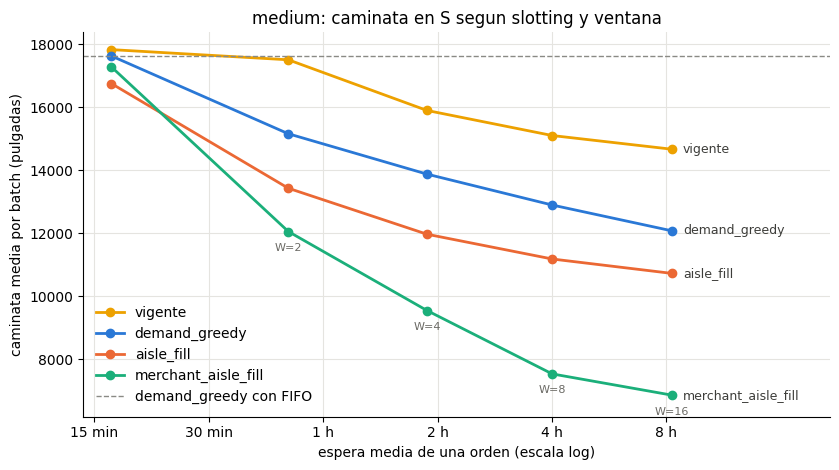

In [29]:
# Caminata media por batch contra la espera media de una orden. Cada punto es una ventana (1, 2, 4, 8, 16).
fig, ax = plt.subplots(figsize=(8.5, 4.8))
for nombre in PLANES:
    g = grilla.query("plan == @nombre").sort_values("ventana")
    x, y = g["espera media (min)"] / 60, g["R_S media"]
    ax.plot(x, y, marker="o", ms=6, lw=2, color=COLORES[nombre], label=nombre)
    ax.annotate(nombre, (x.iloc[-1], y.iloc[-1]), xytext=(8, 0), textcoords="offset points",
                va="center", fontsize=9, color="#3d3d3a")
g = grilla.query("plan == @GANADOR and ventana > 1")
for _, f in g.iterrows():                                   # la ventana de cada punto del ganador
    ax.annotate(f"W={f['ventana']}", (f["espera media (min)"] / 60, f["R_S media"]), xytext=(0, -14),
                textcoords="offset points", ha="center", fontsize=8, color="#6b6a65")
ax.axhline(base, color="#8a8a85", ls="--", lw=1, label="demand_greedy con FIFO")
ax.set_xscale("log", base=2)
ax.set_xticks([0.25, 0.5, 1, 2, 4, 8])
ax.set_xticklabels(["15 min", "30 min", "1 h", "2 h", "4 h", "8 h"])
ax.set_xlim(right=ax.get_xlim()[1] * 2.2)
ax.set_ylim(bottom=grilla["R_S media"].min() * 0.9)
ax.grid(True, color="#e5e4e0", lw=0.8)
for lado in ("top", "right"):
    ax.spines[lado].set_visible(False)
ax.set_xlabel("espera media de una orden (escala log)")
ax.set_ylabel("caminata media por batch (pulgadas)")
ax.set_title(f"{DATASET}: caminata en S segun slotting y ventana")
ax.legend(frameon=False, loc="lower left")
plt.tight_layout()
plt.show()

### 7.3 Semana a semana

El resultado de 7.1 es un promedio sobre todo el test. Caminata media por batch en cada semana del
test, para la referencia, el ganador con FIFO y el ganador con ventana 4. Las semanas de los bordes
estan incompletas; la columna de batches lo muestra.

In [30]:
def por_semana(log):
    return log.groupby(log["timestamp"].dt.to_period("W"))["distance"].agg(["mean", "size"])


ref_s, gan1_s, ganw_s = por_semana(logs[("demand_greedy", 1)]), por_semana(logs[(GANADOR, 1)]), por_semana(logs[(GANADOR, VENTANA)])
semanas = pd.DataFrame({"batches": ref_s["size"], "demand_greedy FIFO": ref_s["mean"],
                        "ganador FIFO": gan1_s["mean"], f"ganador W={VENTANA}": ganw_s["mean"]})
semanas[f"ganador W={VENTANA} vs referencia (%)"] = (semanas[f"ganador W={VENTANA}"] / semanas["demand_greedy FIFO"] - 1) * 100
semanas.round(1)

,batches,demand_greedy FIFO,ganador FIFO,ganador W=4,ganador W=4 vs referencia (%)
timestamp,,,,,
2026-05-25/2026-05-31,279,17634.8,17234.6,9396.6,-46.7
2026-06-01/2026-06-07,315,17681.4,17266.3,9619.0,-45.6
2026-06-08/2026-06-14,315,17645.7,17315.0,9557.4,-45.8
2026-06-15/2026-06-21,315,17605.5,17175.2,9540.9,-45.8
2026-06-22/2026-06-28,315,17538.1,17390.3,9552.8,-45.5
2026-06-29/2026-07-05,90,17672.5,17286.4,9634.9,-45.5


### 7.4 Que aporta cada paso del algoritmo

La caminata que calcula el algoritmo despues de construir y despues de intercambiar, y cuanto tarda
en re-armar todo el test.

In [31]:
pasos = grilla.query("ventana > 1 and plan in ['demand_greedy', @GANADOR]")[
    ["plan", "ventana", "construccion", "algoritmo", "segundos batching"]].copy()
pasos["mejora de los intercambios (%)"] = (pasos["algoritmo"] / pasos["construccion"] - 1) * 100
pasos.round(1)

,plan,ventana,construccion,algoritmo,segundos batching,mejora de los intercambios (%)
6,demand_greedy,2,15408.0,15152.6,2.5,-1.7
7,demand_greedy,4,14202.0,13871.4,2.3,-2.3
8,demand_greedy,8,13197.0,12890.6,2.0,-2.3
9,demand_greedy,16,12409.7,12072.0,2.5,-2.7
16,merchant_aisle_fill,2,12456.4,12049.1,2.1,-3.3
17,merchant_aisle_fill,4,9794.1,9541.9,1.8,-2.6
18,merchant_aisle_fill,8,7931.8,7529.7,2.4,-5.1
19,merchant_aisle_fill,16,7415.7,6856.1,2.5,-7.5


## 8. Sensibilidad a la politica de reposicion

Todo lo anterior supone `home`: el plan se mantiene. En el deposito real, cuando un SKU se agota y se
repone, el sistema decide a donde va, y esa decision puede desarmar el plan. Las tres politicas del
simulador, que solo deciden el destino de cada reposicion de los datos:

- **`home`.** A la ubicacion del plan, o a la libre mas cercana si esta ocupada.
- **`objective_greedy`.** A la ubicacion que minimiza el costo marginal del SKU $s$ en la funcion
  objetivo del QAP, dado donde esta todo en ese momento:
  $$\text{costo}(l) = \lambda\, f_s\, c_l + (1 - \lambda)\, 2 \sum_j a_{sj}\, D(l, \text{ubicacion de } j),$$
  con $\lambda = 0{,}5$, $a_{sj}$ la afinidad de la seccion 0 (que, por la seccion 2, junta SKUs del
  mismo merchant), $D$ la distancia `aisle` y candidatas las ubicaciones libres mas las del SKU. No mira
  el plan.
- **`random`.** Si quedan unidades, repone en el lugar; si el SKU se agoto, con probabilidad 0,9 lo muda
  a una ubicacion libre al azar. Es como se generaron los datos.

Se corre con la referencia y el ganador, con FIFO y con ventana 4.

In [32]:
filas_r = []
for nombre in ["demand_greedy", GANADOR]:
    for w in [1, VENTANA]:
        for politica in ["home", "objective_greedy", "random"]:
            fila, _ = simular(ctx, planes[nombre], pasillos[nombre], w, politica)
            filas_r.append({"plan": nombre, "ventana": w, "reposicion": politica, **fila})
repos = pd.DataFrame(filas_r)
repos["vs greedy FIFO (%)"] = (repos["R_S media"] / base - 1) * 100
repos.set_index(["plan", "ventana", "reposicion"])[["vs greedy FIFO (%)", "mudanzas", "fuera del plan al final",
                                                    "faltantes"]].round(2)

vs greedy FIFO (%)  mudanzas  fuera del plan al final  faltantes
plan                ventana reposicion                                                                        
demand_greedy       1       home                            0.00         0                     0.00          0
                            objective_greedy               -0.00      2018                     0.25          0
                            random                          1.13      6817                     0.37          0
                    4       home                          -21.29         0                     0.00          0
                            objective_greedy               -9.04      2040                     0.26          0
                            random                          0.88      6321                     0.37          0
merchant_aisle_fill 1       home                           -1.96         0                     0.00          0
                            objective_greedy               -0.17       198                     0.02          0
                            random                          1.14      6817                     0.37          0
                    4       home                          -45.86         0                     0.00          0
                            objective_greedy              -38.54       192                     0.02          0
                            random                         -1.09      6292                     0.37          0

**El resultado necesita que el plan se mantenga.** Con `home`, el ganador con ventana 4 gana 45,9%. Con
`objective_greedy` gana 38,5%: hace 192 mudanzas y al final solo el 2% de los SKUs esta fuera de su
ubicacion del plan, porque su termino de afinidad, que en estos datos es el merchant, lleva cada SKU
cerca de los de su merchant. Con `random`, la forma en que se generaron los datos, la ganancia
desaparece (-1,1%): hay 6.292 mudanzas y el 37% de los SKUs termina fuera de su lugar. Con
`demand_greedy` pasa lo mismo, y con `objective_greedy` cae de 21,3% a 9,0%. En un deposito real, el
ganador requiere que las reposiciones se dirijan a la zona del merchant.

## 9. Otros depositos

Los mismos tres planes calculados, con ventanas 1, 4 y 16, en los otros tres depositos de `data/v2`.
`medium-alpha-1.3` es `medium` generado con la demanda mas concentrada en pocos SKUs (parametro
`pareto_alpha` del generador). Primero, que cambia en cada uno:

In [33]:
def perfil(c):
    # Tamano, concentracion de la demanda y ritmo de batches de un deposito.
    pe = c.ds.picking_events
    acumulada = pe["sku"].value_counts(normalize=True).cumsum()
    manifest = json.loads((dataset_dir("v2", c.nombre) / "manifest.json").read_text())
    ubic = pd.Series(c.sim.routing.bay_aisle[c.instance.location_bay]).value_counts()
    return {"pasillos": c.sim.routing.n_aisles, "merchants": len(set(c.instance.merchant_ids)),
            "SKUs": c.instance.n_skus, "SKUs por merchant (max)": int(pd.Series(c.instance.merchant_ids).value_counts().max()),
            "ubicaciones por pasillo": int(ubic.min()), "pareto_alpha": manifest.get("pareto_alpha", "(no figura)"),
            "SKUs para el 50% de las lineas": int((acumulada <= 0.5).sum()),
            "minutos entre batches": round(c.minutos_por_batch, 1), "batches de test": c.split.test["batch_id"].nunique()}


perfiles, filas_o = {DATASET: perfil(ctx)}, []
for nombre_dep in OTROS:
    c = preparar(nombre_dep)
    perfiles[nombre_dep] = perfil(c)
    ps = planes_de(c)
    for nombre in ["demand_greedy", "aisle_fill", GANADOR]:
        sa_c = pasillo_por_sku(c, ps[nombre])
        for w in [1, VENTANA, 16]:
            fila, _ = simular(c, ps[nombre], sa_c, w)
            filas_o.append({"deposito": nombre_dep, "plan": nombre, "ventana": w, **fila})
    del c, ps
    gc.collect()
otros = pd.DataFrame(filas_o)
ref = otros.query("plan == 'demand_greedy' and ventana == 1").set_index("deposito")["R_S media"]
otros["vs greedy FIFO (%)"] = (otros["R_S media"] / otros["deposito"].map(ref) - 1) * 100
print("diferencia maxima entre simulacion y algoritmo:", round((otros["R_S media"] - otros["algoritmo"]).abs().max(), 3))
print("mudanzas:", otros["mudanzas"].sum())
pd.DataFrame(perfiles)

diferencia maxima entre simulacion y algoritmo: 0.0
mudanzas: 0


,medium,small,medium-alpha-1.3,big
pasillos,8,4,8.0,16
merchants,50,4,50.0,100
SKUs,6912,1728,6912.0,24883
SKUs por merchant (max),157,442,157.0,287
ubicaciones por pasillo,960,480,960.0,1728
pareto_alpha,(no figura),(no figura),1.3,(no figura)
SKUs para el 50% de las lineas,318,35,227.0,755
minutos entre batches,32.0,240.0,32.0,14.4
batches de test,1629,218,1629.0,3620


Diferencia contra `demand_greedy` con FIFO de cada deposito:

In [34]:
otros.pivot(index=["deposito", "plan"], columns="ventana", values="vs greedy FIFO (%)").round(1)

ventana                                1     4     16
deposito         plan                                
big              aisle_fill          -9.1 -38.5 -50.7
                 demand_greedy        0.0 -29.0 -40.9
                 merchant_aisle_fill -2.1 -51.4 -70.9
medium-alpha-1.3 aisle_fill          -9.4 -34.8 -40.7
                 demand_greedy        0.0 -24.9 -34.4
                 merchant_aisle_fill  0.1 -45.1 -60.7
small            aisle_fill          -0.6  -6.8  -9.7
                 demand_greedy        0.0  -1.3  -0.9
                 merchant_aisle_fill -0.2 -27.8 -37.6

Espera media en minutos, que depende del ritmo de batches de cada deposito, y lineas faltantes por corrida:

In [35]:
pd.concat({"espera media (min)": otros.query("plan == @GANADOR").pivot(index="deposito", columns="ventana", values="espera media (min)").round(0),
           "faltantes (max entre planes)": otros.pivot_table(index="deposito", columns="ventana", values="faltantes", aggfunc="max")}, axis=1)

espera media (min)                faltantes (max entre planes)       
ventana                          1      4       16                           1   4  16
deposito                                                                              
big                             7.0   51.0   223.0                            7  20  8
medium-alpha-1.3               17.0  113.0   496.0                            0   0  0
small                         125.0  840.0  3659.0                            0   0  0

**El patron se repite en los otros tres depositos.** Con ventana 4 el ganador gana 51,4% en `big`,
45,1% en `medium-alpha-1.3` y 27,8% en `small`; con ventana 16, 70,9%, 60,7% y 37,6%. En los tres es el
mejor plan con re-batching, y con FIFO queda cerca de la referencia (entre -2,1% y +0,1%).

- **`big`** tiene 16 pasillos, 100 merchants y sale un batch cada 14,4 minutos, asi que la misma ventana
  espera menos: 51 minutos de media con ventana 4. Sus faltantes, hasta 20 lineas por corrida, aparecen
  tambien con FIFO, asi que no los produce el re-batching.
- **`medium-alpha-1.3`** concentra mas la demanda (227 SKUs hacen la mitad de las lineas, contra 318 en
  `medium`). Eso ayuda a `aisle_fill` con FIFO (-9,4%) y casi no cambia al ganador.
- **`small`** tiene 4 merchants, uno por pasillo, y sale un batch cada 240 minutos, asi que sus esperas
  (14 horas con ventana 4) no son realistas.

## 10. Los demas metodos probados

La grilla del notebook 05 corrio, con esta misma simulacion (recorrido en S, reposicion `home`, mismo
test), otras familias de slotting. Aca se leen sus resultados guardados en `results/05_combinatoria`,
para ubicar al ganador entre ellas. Las familias:

- **`linear_assignment`.** El problema lineal $\min \sum_i f_i\, c_{l(i)}$ resuelto exacto como un
  problema de transporte. Da lo mismo que `demand_greedy`.
- **`bilevel` (grupo/zona).** Agrupa los SKUs (por merchant, o en clases A, B y C de demanda), reparte
  las ubicaciones entre los grupos con un problema de transporte y dentro de cada zona ordena por
  demanda. Las zonas son bandas por distancia al dock (`dock`) o pasillo por pasillo (`aisle_order`).
- **`swap_search`.** Busqueda local por intercambios sobre el QAP,
  $\min\; \lambda \sum_i f_i\, c_{l(i)} + (1 - \lambda) \sum_{i,j} a_{ij}\, D(l(i), l(j))$, con $l(i)$ la
  ubicacion del SKU $i$, desde un plan inicial. $\lambda$ pesa el termino de demanda y $1 - \lambda$
  el de afinidad: $\lambda = 0$ es solo afinidad. Se probaron 16 variantes de $\lambda$, metrica, unidad y
  filtro de la afinidad, distancia $D$, normalizacion, vecindad y plan inicial. Por su costo de computo
  se corrio solo en `small`, `medium` y `medium-alpha-1.3`.

Para cada familia se muestra la mejor configuracion con ventana 4, con su valor con FIFO; en
`swap_search` se separa por plan inicial y la columna `variante` da sus parametros. En `big` no hay
`swap_search`.

In [36]:
from abs_affinity_based_slotting.experiments.runner import load_results

r05 = load_results(PROJECT_ROOT / "results" / "05_combinatoria")
r05 = r05[(r05["routing"] == "s_shape") & (r05["replenishment"] == "home") & r05["dataset"].isin([DATASET, "big"])].copy()


def familia(x):
    if x["slot_method"] == "bilevel":
        return f"bilevel {x['slot_clustering']}/{x['slot_zone_cost']}"
    if x["slot_method"] == "swap_search":
        return f"swap_search desde {x['slot_seed']}"
    return x["slot_method"]


def variante(x):
    if x["slot_method"] != "swap_search":
        return ""
    return (f"lambda={x['slot_lam']}, vecindad={x['slot_neighborhood']}, D={x['pair_distance']}, "
            f"afinidad={x['affinity_metric']}/{x['cooccurrence_col']}/{x['affinity_filter']}, normalize={x['normalize']}")


r05["familia"], r05["variante"] = r05.apply(familia, axis=1), r05.apply(variante, axis=1)
ref05 = r05.query("slot_method == 'demand_greedy' and window == 1").groupby("dataset")["mean_distance"].median()
r05["vs greedy FIFO (%)"] = (r05["mean_distance"] / r05["dataset"].map(ref05) - 1) * 100
t = r05[r05["window"].isin([1, VENTANA])].pivot_table(index=["dataset", "familia", "variante"], columns="window",
                                                     values="vs greedy FIFO (%)", aggfunc="median")
mejor = t.sort_values(VENTANA).groupby(level=["dataset", "familia"]).head(1)
mejor = mejor.rename(columns={1: "FIFO", VENTANA: f"W={VENTANA}"}).round(1).reset_index("variante")
with pd.option_context("display.max_colwidth", None):
    display(mejor.sort_values(["dataset", f"W={VENTANA}"]))

window                                                                                                                      variante  FIFO   W=4
dataset familia                                                                                                                                 
big     bilevel merchant/aisle_order                                                                                                  -1.4 -52.1
        merchant_aisle_fill                                                                                                           -2.1 -51.4
        aisle_fill                                                                                                                    -9.1 -38.5
        bilevel demand_class/aisle_order                                                                                              -7.3 -35.2
        demand_greedy                                                                                                                  0.0 -29.0
        bilevel demand_class/dock                                                                                                      0.3 -28.9
        bilevel merchant/dock                                                                                                         17.4 -19.7
        vigente                                                                                                                       19.8  -0.1
medium  merchant_aisle_fill                                                                                                           -2.0 -45.9
        swap_search desde merchant_aisle_fill  lambda=0.5, vecindad=bay, D=aisle, afinidad=jaccard/order_id/top_k:10, normalize=True  -0.8 -43.8
        bilevel merchant/aisle_order                                                                                                  -0.9 -43.5
        swap_search desde aisle_fill           lambda=0.5, vecindad=bay, D=aisle, afinidad=jaccard/order_id/top_k:10, normalize=True  -2.6 -41.2
        swap_search desde demand_greedy        lambda=0.5, vecindad=bay, D=aisle, afinidad=jaccard/order_id/top_k:20, normalize=True   0.1 -39.5
        aisle_fill                                                                                                                    -5.0 -32.1
        bilevel demand_class/aisle_order                                                                                              -3.9 -29.7
        linear_assignment                                                                                                             -0.1 -21.4
        demand_greedy                                                                                                                  0.0 -21.3
        bilevel demand_class/dock                                                                                                     -0.2 -21.2
        bilevel merchant/dock                                                                                                          1.0 -19.6
        vigente                                                                                                                        1.1  -9.8

El peso de la afinidad dentro de `swap_search`, en `medium`, arrancando de `demand_greedy` y con el
resto de los parametros fijos (vecindad `bay`, distancia `aisle`, `jaccard` por orden, 10 vecinos,
normalizada). La primera fila es `demand_greedy` sin intercambios.

In [37]:
sw = r05[(r05["dataset"] == DATASET) & (r05["slot_method"] == "swap_search") & (r05["slot_seed"] == "demand_greedy")
         & (r05["slot_neighborhood"] == "bay") & (r05["pair_distance"] == "aisle") & (r05["affinity_metric"] == "jaccard")
         & (r05["cooccurrence_col"] == "order_id") & (r05["affinity_filter"] == "top_k:10") & r05["normalize"]]
por_lambda = sw[sw["window"].isin([1, VENTANA])].pivot_table(index="slot_lam", columns="window", values="vs greedy FIFO (%)")
sin_swap = r05.query("dataset == @DATASET and slot_method == 'demand_greedy'").pivot_table(columns="window", values="vs greedy FIFO (%)")
por_lambda = pd.concat([sin_swap[[1, VENTANA]].rename(index={"vs greedy FIFO (%)": "sin intercambios"}),
                        por_lambda.rename(index=lambda x: f"lambda = {x}")])
por_lambda.rename(columns={1: "FIFO", VENTANA: f"W={VENTANA}"}).round(1)

window,FIFO,W=4
sin intercambios,-0.0,-21.3
lambda = 0.0,-0.4,-35.6
lambda = 0.25,-0.6,-35.0
lambda = 0.5,-0.5,-33.4
lambda = 0.75,-0.4,-33.0


Control: la grilla del notebook 05 y la seccion 7 dan lo mismo para el ganador en `medium`:

In [38]:
print("notebook 05:", round(r05.query("slot_method == @GANADOR and window == @VENTANA and dataset == @DATASET")["vs greedy FIFO (%)"].median(), 1),
      "| seccion 7:", round(v[(GANADOR, VENTANA)], 1))

notebook 05: -45.9 | seccion 7: -45.9


**El ganador es el mejor de todas las familias probadas en `medium`, y empata en `big`.** La unica que
se le acerca es `bilevel merchant/aisle_order`, que es la misma idea, agrupar por merchant y armar las
zonas pasillo por pasillo, implementada con un problema de transporte: queda 2,4 puntos abajo en
`medium` (-43,5%) y 0,7 arriba en `big` (-52,1% contra -51,4%). Con zonas por distancia al dock
(`merchant/dock`), el mismo agrupamiento por merchant da -19,6% en `medium` y -19,7% en `big`, porque
una banda por distancia al dock cruza varios pasillos y cada merchant queda repartido entre ellos.

**El QAP (`swap_search`) no supera la regla.** Desde el plan ganador, los intercambios lo empeoran a
-43,8%; desde `aisle_fill` llegan a -41,2% y desde `demand_greedy` a -39,5% como mejor variante.
`linear_assignment` da lo mismo que `demand_greedy`.

**La afinidad del QAP ayuda, pero no alcanza.** Desde `demand_greedy`, cualquier peso de la afinidad
lleva la caminata con ventana 4 de -21,3% a entre -33,0% y -35,6%, y el mejor es $\lambda = 0$, solo
afinidad. Los intercambios redescubren en parte el agrupamiento por merchant, que es la afinidad que hay
en los datos, pero quedan unos 10 puntos por debajo de la regla que lo impone directamente.

## 11. Lectura

Las cifras son la caminata media en S por batch, simulada sobre el periodo de test, contra
`demand_greedy` con FIFO.

**La afinidad de estos datos es el merchant.** Dos SKUs del mismo merchant se piden juntos 43,4 veces
mas que si fueran independientes, y dos de merchants distintos nunca (2.1). Dentro de un merchant no hay
afinidad entre SKUs mas alla de la popularidad: los datos barajados reproducen la co-ocurrencia real
(2.2).

**El slotting ganador la incorpora en la forma que paga con recorrido en S.** Con este recorrido la
caminata depende solo de los pasillos visitados (3), asi que la afinidad sirve para decidir que SKUs
comparten pasillo. `merchant_aisle_fill` pone cada merchant en un pasillo, sin parametros, y una orden
toca 1,04 pasillos, con el 96% de las ordenes en uno solo (4).

**Rinde si los batches se arman por pasillo.** Con FIFO gana 2,0%, porque un batch de 25 ordenes de
unos 20 merchants visita casi todos los pasillos igual. Con re-batching de ventana 4 gana 45,9%,
contra 21,3% del mismo re-batching con `demand_greedy`: la combinacion vale mas que la suma de las
partes (7.1). Es estable semana a semana, entre -45,5% y -46,7% (7.3), y re-armar todo el test tarda
entre 2,2 y 2,6 segundos (7.4).

**Se repite en los demas depositos.** Con ventana 4 gana 51,4% en `big`, 45,1% en `medium-alpha-1.3`
y 27,8% en `small` (9). Ninguna otra familia probada lo supera; solo la version binivel de la misma idea
empata en `big` (10).

**Tiene dos costos.** El primero es la espera: la media pasa de 17 minutos con FIFO a 113 minutos con
ventana 4 en `medium`, y a 51 minutos en `big`, donde los batches salen mas seguido (7.2 y 9); ventanas
mas grandes ganan mas (61,1% con ventana 16) y esperan mas. El segundo es mantener el plan: con
reposiciones al azar la ganancia desaparece, y con `objective_greedy` queda en 38,5% (8).

**Lo que este notebook no mide.**
- La hora real de llegada de las ordenes: la espera sale de una regla (5.5) y el maximo tolerable lo
  decide la operacion.
- La congestion: con merchants por pasillo, dos batches simultaneos comparten pasillo con mas
  probabilidad, y el simulador no la modela.
- Merchants de tamanos muy distintos: en los datos todos piden casi lo mismo (4); uno mucho mas grande
  que un pasillo quedaria partido y habria que revisar la regla.
- El costo de llevar el deposito al plan nuevo, que no se cuenta (6), y el tiempo de picking, porque
  todo se mide en distancia.